# 01 · Primeira exploração do dataset

**Objetivo.** Conhecer o `application_train.csv` do Home Credit Default Risk: o que ele contém,
como está distribuído, onde há problemas e o que se relaciona com a inadimplência. Este notebook
**só observa**: o que se vê aqui vira perguntas e, depois, decisões, mas nenhuma decisão é
tomada neste documento.

> **Privacidade (LGPD):** só são exibidos agregados e distribuições; nenhuma linha individual
> de cliente é impressa.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from credit_drift.data import DAYS_EMPLOYED_SENTINEL, age_years, employment_years, load_application_train

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = load_application_train()
y = df["TARGET"]
print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas")

307,511 linhas x 122 colunas


## 1. O que é cada linha

Cada linha é **um pedido de crédito** de um cliente (`SK_ID_CURR` identifica o pedido). A coluna
`TARGET` vale 1 quando o cliente teve dificuldade de pagamento e 0 caso contrário. As demais
colunas descrevem o cliente, o pedido e dados externos. Agrupando pelo nome:

In [2]:
def group(c):
    if c in ("SK_ID_CURR", "TARGET"): return "identificação / alvo"
    if c.startswith("EXT_SOURCE"): return "scores externos (EXT_SOURCE_1/2/3)"
    if c.startswith("FLAG_DOCUMENT"): return "documentos entregues (FLAG_DOCUMENT_*)"
    if c.endswith(("_AVG", "_MODE", "_MEDI")) or c == "TOTALAREA_MODE": return "características do imóvel (*_AVG/_MODE/_MEDI)"
    if c.startswith("AMT_REQ_CREDIT_BUREAU"): return "consultas ao bureau (AMT_REQ_CREDIT_BUREAU_*)"
    if "SOCIAL_CIRCLE" in c: return "círculo social (*_SOCIAL_CIRCLE)"
    if c.startswith("AMT_"): return "valores financeiros (AMT_*)"
    if c.startswith("DAYS_"): return "datas relativas em dias (DAYS_*)"
    if c.startswith(("REG_", "LIVE_", "REGION_")): return "região / endereço"
    if c.startswith("FLAG_"): return "indicadores (FLAG_*)"
    return "demais (perfil, contrato, ocupação...)"

groups = pd.Series({c: group(c) for c in df.columns}).value_counts()
print(groups.to_string())
print()
print("Tipos:", df.dtypes.map(lambda t: "texto" if t == "object" else "numérico").value_counts().to_dict())
print("Colunas de data absoluta:", [c for c in df if "DATE" in c.upper()] or "nenhuma")

características do imóvel (*_AVG/_MODE/_MEDI)    47
documentos entregues (FLAG_DOCUMENT_*)           20
demais (perfil, contrato, ocupação...)           14
região / endereço                                 9
indicadores (FLAG_*)                              8
consultas ao bureau (AMT_REQ_CREDIT_BUREAU_*)     6
datas relativas em dias (DAYS_*)                  5
círculo social (*_SOCIAL_CIRCLE)                  4
valores financeiros (AMT_*)                       4
scores externos (EXT_SOURCE_1/2/3)                3
identificação / alvo                              2

Tipos: {'numérico': 106, 'texto': 16}
Colunas de data absoluta: nenhuma


**Observações.**
- Boa parte das colunas (imóvel, documentos, bureau) são grupos de muitas colunas parecidas.
- As datas são **relativas** (`DAYS_BIRTH` = dias antes do pedido, valores negativos); **não há data
  absoluta** nem ordem temporal entre as linhas.

## 2. O alvo

Inadimplentes: 24,825 de 307,511 (8.07%)


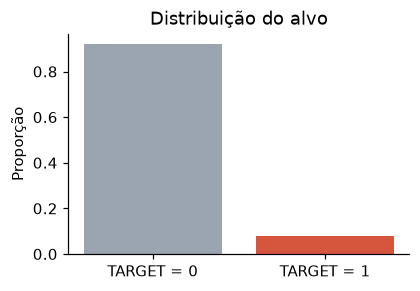

In [3]:
rate = y.mean()
print(f"Inadimplentes: {y.sum():,} de {len(y):,} ({rate:.2%})")
fig, ax = plt.subplots(figsize=(4, 2.6))
ax.bar(["TARGET = 0", "TARGET = 1"], [(y == 0).mean(), (y == 1).mean()], color=["#9aa5b1", "#d6553d"])
ax.set_ylabel("Proporção"); ax.set_title("Distribuição do alvo")
plt.show()

**Observações.**
- O alvo é **muito desbalanceado**: ≈8% de positivos. Um modelo que dissesse "ninguém inadimple"
  acertaria 92% das vezes e não serviria para nada, logo a acurácia não é uma boa medida aqui.
- Em qualquer subgrupo pequeno haverá poucos positivos (um grupo de 1.000 clientes tem ≈80).

## 3. Dados ausentes

Não basta contar nulos: a **causa** da ausência importa. Três casos clássicos: MCAR (aleatória),
MAR (depende de outras variáveis observadas) e MNAR (depende do próprio valor que falta).

Colunas com algum nulo: 67 de 122
até 10%    10
10–30%      7
30–50%      9
50–70%     41


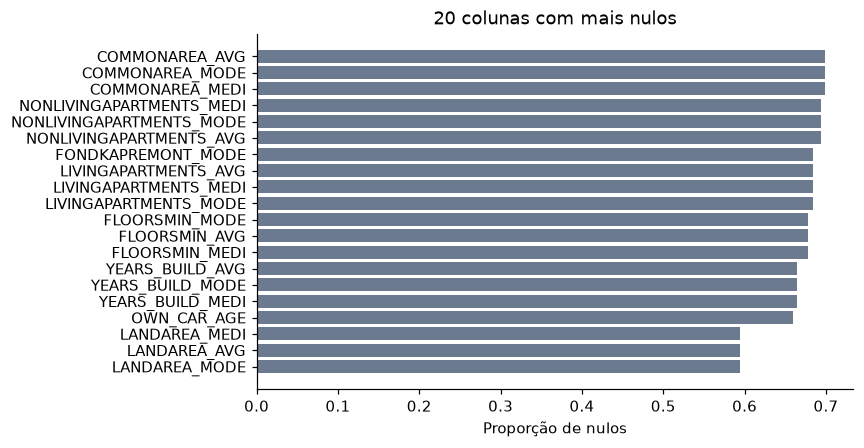

In [4]:
na = df.isna().mean().sort_values(ascending=False)
bands = pd.cut(na[na > 0], [0, .1, .3, .5, .7], labels=["até 10%", "10–30%", "30–50%", "50–70%"])
print(f"Colunas com algum nulo: {(na > 0).sum()} de {df.shape[1]}")
print(bands.value_counts().sort_index().to_string())
fig, ax = plt.subplots(figsize=(7, 4.2))
top = na.head(20)[::-1]
ax.barh(top.index, top.values, color="#6b7a8f"); ax.set_xlabel("Proporção de nulos")
ax.set_title("20 colunas com mais nulos")
plt.show()

### 3.1 O bloco de colunas do imóvel some em conjunto
As colunas de características do imóvel (`*_AVG`, `*_MODE`, `*_MEDI`, 47 no total) estão
entre as mais ausentes. Elas somem **juntas**? E a ausência tem relação com o resto?

In [5]:
house = [c for c in df if c.endswith(("_AVG", "_MODE", "_MEDI"))]
share_missing = df[house].isna().mean(axis=1)
blk = share_missing > 0.9
print(f"{len(house)} colunas | linhas com o bloco quase todo ausente: {blk.mean():.1%} | sem nenhum nulo: {(share_missing == 0).mean():.1%}")
cmp = pd.DataFrame({
    "bloco ausente": [y[blk].mean(), df.AMT_INCOME_TOTAL[blk].median(), df.REGION_RATING_CLIENT[blk].mean()],
    "bloco presente": [y[~blk].mean(), df.AMT_INCOME_TOTAL[~blk].median(), df.REGION_RATING_CLIENT[~blk].mean()],
}, index=["taxa de inadimplência", "renda mediana", "rating médio da região"])
cmp.round(3)

47 colunas | linhas com o bloco quase todo ausente: 48.4% | sem nenhum nulo: 25.6%


,bloco ausente,bloco presente
taxa de inadimplência,0.092,0.070
renda mediana,135000.000,157500.000
rating médio da região,2.125,1.984


**Observações.**
- O bloco some em conjunto: quase metade das linhas (48%) tem as colunas do imóvel ausentes e só
  26% não têm nenhum nulo.
- Quem está sem dados do imóvel **inadimple mais** (≈9,2% vs ≈7,0%), tem renda mediana menor e vive
  em regiões pior avaliadas. A ausência não parece aleatória: depende de outras variáveis
  observadas (padrão MAR) e carrega informação.

### 3.2 Outras ausências

In [6]:
rows = []
for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "OWN_CAR_AGE", "OCCUPATION_TYPE"]:
    m = df[c].isna()
    rows.append((c, m.mean(), y[m].mean(), y[~m].mean()))
print(pd.DataFrame(rows, columns=["coluna", "% nulo", "inadimplência se nulo", "inadimplência se presente"]).round(4).to_string(index=False))
has_car = df.FLAG_OWN_CAR == "Y"
print(f"\nOWN_CAR_AGE nulo entre quem NÃO tem carro: {df.OWN_CAR_AGE[~has_car].isna().mean():.1%} | entre quem tem: {df.OWN_CAR_AGE[has_car].isna().mean():.1%}")

         coluna  % nulo  inadimplência se nulo  inadimplência se presente
   EXT_SOURCE_1  0.5638                 0.0852                     0.0750
   EXT_SOURCE_2  0.0021                 0.0788                     0.0807
   EXT_SOURCE_3  0.1983                 0.0931                     0.0777
    OWN_CAR_AGE  0.6599                 0.0850                     0.0724
OCCUPATION_TYPE  0.3135                 0.0651                     0.0879

OWN_CAR_AGE nulo entre quem NÃO tem carro: 100.0% | entre quem tem: 0.0%


**Observações.**
- `OWN_CAR_AGE` é nulo **exatamente** quando o cliente não tem carro: não é falha de coleta, é um
  valor que não existe (ausência estrutural).
- `EXT_SOURCE_1` (56% nulo) e `EXT_SOURCE_3` (20%) também têm inadimplência maior quando nulos
  (≈8,5% e ≈9,3%, contra ≈7,5% e ≈7,8% quando presentes).
- Pergunta em aberto: por que alguns clientes não têm score externo?

## 4. Valores, faixas e anomalias

       idade (anos)  renda anual  valor do crédito  parcela (annuity)
count      307511.0     307511.0          307511.0           307499.0
mean           43.9     168797.9          599026.0            27108.6
std            11.9     237123.1          402490.8            14493.7
min            20.5      25650.0           45000.0             1615.5
25%            34.0     112500.0          270000.0            16524.0
50%            43.1     147150.0          513531.0            24903.0
75%            53.9     202500.0          808650.0            34596.0
max            69.1  117000000.0         4050000.0           258025.5

Renda > 1 milhão: 250 linhas | máx = 117,000,000
Renda <= 0: 0 | renda nula: 0 | idade < 18: 0
CODE_GENDER: {'F': 202448, 'M': 105059, 'XNA': 4}
CNT_CHILDREN máx: 19 | OBS_30_CNT_SOCIAL_CIRCLE máx: 348


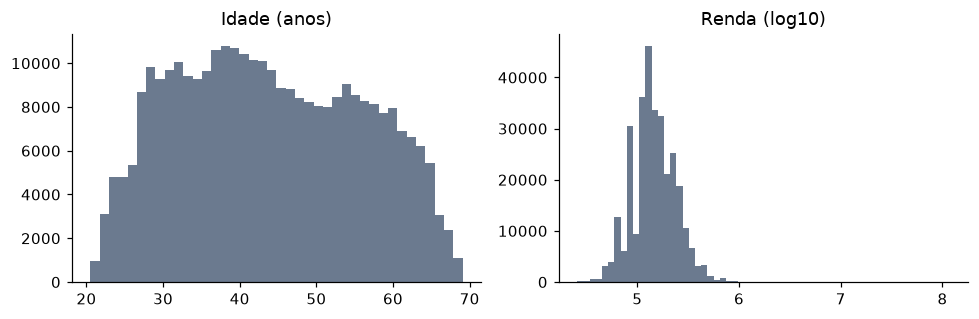

In [7]:
age = age_years(df)
print(pd.DataFrame({
    "idade (anos)": age.describe(),
    "renda anual": df.AMT_INCOME_TOTAL.describe(),
    "valor do crédito": df.AMT_CREDIT.describe(),
    "parcela (annuity)": df.AMT_ANNUITY.describe(),
}).round(1).to_string())
print()
print(f"Renda > 1 milhão: {(df.AMT_INCOME_TOTAL > 1e6).sum()} linhas | máx = {df.AMT_INCOME_TOTAL.max():,.0f}")
print(f"Renda <= 0: {(df.AMT_INCOME_TOTAL <= 0).sum()} | renda nula: {df.AMT_INCOME_TOTAL.isna().sum()} | idade < 18: {(age < 18).sum()}")
print("CODE_GENDER:", df.CODE_GENDER.value_counts().to_dict())
print(f"CNT_CHILDREN máx: {df.CNT_CHILDREN.max()} | OBS_30_CNT_SOCIAL_CIRCLE máx: {df.OBS_30_CNT_SOCIAL_CIRCLE.max():.0f}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(age, bins=40, color="#6b7a8f"); ax[0].set_title("Idade (anos)")
ax[1].hist(np.log10(df.AMT_INCOME_TOTAL), bins=60, color="#6b7a8f"); ax[1].set_title("Renda (log10)")
plt.tight_layout(); plt.show()

### 4.1 O valor 365243 em `DAYS_EMPLOYED`
`DAYS_EMPLOYED` deveria ser negativo (dias de emprego antes do pedido). Mas:

In [8]:
sent = df.DAYS_EMPLOYED == DAYS_EMPLOYED_SENTINEL
print(f"DAYS_EMPLOYED = {DAYS_EMPLOYED_SENTINEL} (≈ {DAYS_EMPLOYED_SENTINEL / 365.25:,.0f} anos): {sent.sum():,} linhas ({sent.mean():.1%})")
print(df.assign(sentinela=sent).groupby("NAME_INCOME_TYPE").sentinela.mean().round(3).to_string())
print(f"\nOCCUPATION_TYPE nulo entre essas linhas: {df.OCCUPATION_TYPE[sent].isna().mean():.0%} | demais: {df.OCCUPATION_TYPE[~sent].isna().mean():.1%}")
print(f"Inadimplência com o valor: {y[sent].mean():.2%} | sem: {y[~sent].mean():.2%}")

DAYS_EMPLOYED = 365243 (≈ 1,000 anos): 55,374 linhas (18.0%)


NAME_INCOME_TYPE
Businessman             0.0
Commercial associate    0.0
Maternity leave         0.0
Pensioner               1.0
State servant           0.0
Student                 0.0
Unemployed              1.0
Working                 0.0

OCCUPATION_TYPE nulo entre essas linhas: 100% | demais: 16.3%
Inadimplência com o valor: 5.40% | sem: 8.66%


**Observações.**
- Idade vai de 20 a 69 anos; **não há** renda nula, renda ≤ 0 nem idade < 18 neste conjunto.
- A renda tem **cauda extrema**: máx. de 117 milhões, e 250 linhas acima de 1 milhão, contra mediana
  de ≈147 mil.
- `CODE_GENDER` tem 4 linhas `XNA` (valor fora de F/M).
- `365243` não é um valor real (≈1.000 anos). É um **código para "não empregado"**: aparece em 100%
  dos aposentados e desempregados, em nenhuma outra categoria, sempre sem ocupação informada.
  Tratado como número, distorce médias, desvios e correlações.

## 5. Duplicatas

In [9]:
print(f"IDs duplicados: {df.SK_ID_CURR.duplicated().sum()} | linhas duplicadas (exceto ID): {df.drop(columns='SK_ID_CURR').duplicated().sum()}")

IDs duplicados: 0 | linhas duplicadas (exceto ID): 0


**Observação.** Sem duplicatas de ID nem de linha inteira.

## 6. O que se relaciona com a inadimplência

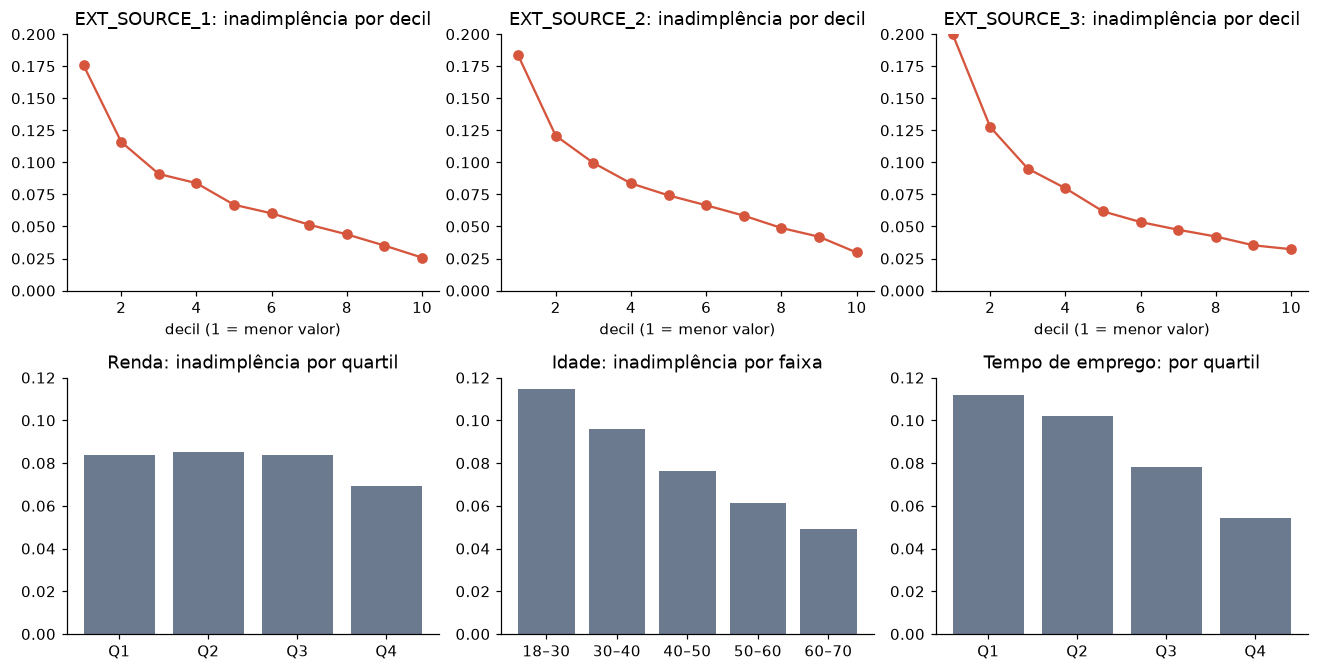


Inadimplência por CODE_GENDER:
               taxa       n
CODE_GENDER                
F            0.0700  202448
M            0.1014  105059
XNA          0.0000       4

Inadimplência por NAME_CONTRACT_TYPE:
                      taxa       n
NAME_CONTRACT_TYPE                
Cash loans          0.0835  278232
Revolving loans     0.0548   29279

Inadimplência por NAME_EDUCATION_TYPE:
                                 taxa       n
NAME_EDUCATION_TYPE                          
Academic degree                0.0183     164
Higher education               0.0536   74863
Incomplete higher              0.0848   10277
Lower secondary                0.1093    3816
Secondary / secondary special  0.0894  218391


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, c in zip(axes[0], ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    g = y.groupby(pd.qcut(df[c], 10, duplicates="drop"), observed=True).mean()
    ax.plot(range(1, len(g) + 1), g.values, marker="o", color="#d6553d")
    ax.set_title(f"{c}: inadimplência por decil"); ax.set_xlabel("decil (1 = menor valor)")
    ax.set_ylim(0, 0.2)
inc = y.groupby(pd.qcut(df.AMT_INCOME_TOTAL, 4), observed=True).mean()
axes[1][0].bar(["Q1", "Q2", "Q3", "Q4"], inc.values, color="#6b7a8f"); axes[1][0].set_title("Renda: inadimplência por quartil")
ag = y.groupby(pd.cut(age_years(df), [18, 30, 40, 50, 60, 70]), observed=True).mean()
axes[1][1].bar([f"{int(i.left)}–{int(i.right)}" for i in ag.index], ag.values, color="#6b7a8f"); axes[1][1].set_title("Idade: inadimplência por faixa")
ey = y.groupby(pd.qcut(employment_years(df), 4, duplicates="drop"), observed=True).mean()
axes[1][2].bar(["Q1", "Q2", "Q3", "Q4"][:len(ey)], ey.values, color="#6b7a8f"); axes[1][2].set_title("Tempo de emprego: por quartil")
for ax in axes[1]:
    ax.set_ylim(0, 0.12)
plt.tight_layout(); plt.show()
for col in ["CODE_GENDER", "NAME_CONTRACT_TYPE", "NAME_EDUCATION_TYPE"]:
    print(f"\nInadimplência por {col}:\n" + y.groupby(df[col]).agg(["mean", "size"]).round(4).rename(columns={"mean": "taxa", "size": "n"}).to_string())

**Observações.**
- As três `EXT_SOURCE` (scores externos) têm relação **forte e monótona**: quanto menor o score,
  maior a inadimplência.
- Renda, idade e tempo de emprego têm relação **bem mais fraca**. A renda mal diferencia os três
  primeiros quartis.
- Homens inadimplem mais que mulheres (≈10,1% vs ≈7,0%). Empréstimos em dinheiro (`Cash loans`)
  e escolaridade mais baixa também se associam a mais inadimplência (ver tabelas acima).

## 7. Correlações e sinais de vazamento (leakage)

*Vazamento* é quando uma coluna contém informação que só existiria depois do resultado,
fazendo um modelo parecer melhor do que realmente é. Um sinal clássico: uma única coluna que prevê
o alvo quase perfeitamente.

**Como é calculado o "poder preditivo isolado":** para cada coluna numérica, o valor bruto é usado
como se fosse um score, e calcula-se o AUC-ROC contra o alvo, usando só as linhas em que o valor
existe (colunas com menos de 1.000 valores são puladas). Depois toma-se `max(AUC, 1 − AUC)`, porque
a direção não importa: uma coluna que sobe quando a inadimplência cai dá 0,3, e o 0,7 equivalente
é o que interessa. Interpretação: a probabilidade de um inadimplente aleatório ter valor maior
(ou menor) que um adimplente aleatório. 0,5 = nenhuma separação. Limitação: enxerga uma coluna por
vez e supõe tendência monótona.

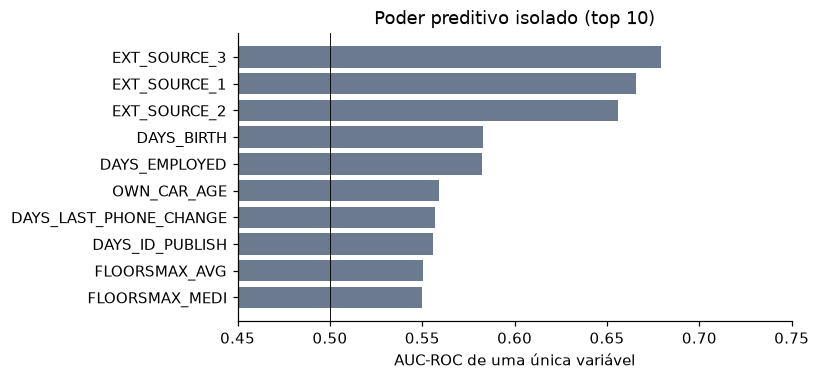

Maior AUC isolado: 0.679 (EXT_SOURCE_3)


In [11]:
num = df.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"]).copy()
num["DAYS_EMPLOYED"] = num["DAYS_EMPLOYED"].replace(DAYS_EMPLOYED_SENTINEL, np.nan)
auc = {}
for c in num:
    v, k = num[c], num[c].notna()
    if k.sum() > 1000 and v[k].nunique() > 1:
        a = roc_auc_score(y[k], v[k])
        auc[c] = max(a, 1 - a)
auc = pd.Series(auc).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(auc.head(10).index[::-1], auc.head(10).values[::-1], color="#6b7a8f")
ax.axvline(0.5, color="k", lw=.6); ax.set_xlim(0.45, 0.75); ax.set_xlabel("AUC-ROC de uma única variável")
ax.set_title("Poder preditivo isolado (top 10)")
plt.show()
print(f"Maior AUC isolado: {auc.iloc[0]:.3f} ({auc.index[0]})")

In [12]:
ratios = pd.Series({
    "AMT_ANNUITY / AMT_INCOME_TOTAL": (df.AMT_ANNUITY / df.AMT_INCOME_TOTAL).corr(y),
    "AMT_CREDIT / AMT_INCOME_TOTAL": (df.AMT_CREDIT / df.AMT_INCOME_TOTAL).corr(y),
    "AMT_CREDIT / AMT_GOODS_PRICE": (df.AMT_CREDIT / df.AMT_GOODS_PRICE).corr(y),
    "EXT_SOURCE_2 (referência)": df.EXT_SOURCE_2.corr(y),
}).round(3)
print("Correlação linear com o alvo:\n" + ratios.to_string())
house_num = df[house].select_dtypes("number")
cm = house_num.corr().abs().where(np.triu(np.ones((house_num.shape[1],) * 2, dtype=bool), 1))
print(f"\nColunas numéricas do imóvel: {house_num.shape[1]} | pares com |correlação| > 0,95: {int((cm > 0.95).sum().sum())}")

Correlação linear com o alvo:
AMT_ANNUITY / AMT_INCOME_TOTAL    0.014
AMT_CREDIT / AMT_INCOME_TOTAL    -0.008
AMT_CREDIT / AMT_GOODS_PRICE      0.069
EXT_SOURCE_2 (referência)        -0.160



Colunas numéricas do imóvel: 43 | pares com |correlação| > 0,95: 42


**Observações.**
- O maior AUC isolado é ≈0,68 (`EXT_SOURCE_3`), seguido das outras duas `EXT_SOURCE`; nenhuma coluna
  chega perto de separar o alvo sozinha, então **não há sinal de vazamento**.
- Razões financeiras simples (parcela/renda, crédito/renda) têm correlação linear **quase nula**
  com o alvo.
- As colunas do imóvel são em grande parte **versões da mesma medida** (`_AVG`, `_MODE`, `_MEDI`),
  com muitos pares quase idênticos (|correlação| > 0,95).

## 8. Resumo do que vimos

**Fatos**
1. 307.511 pedidos × 122 colunas; ≈8% de inadimplentes (desbalanceado).
2. Sem data absoluta: só datas relativas ao pedido.
3. 67 colunas têm nulos; 41 têm mais da metade ausente. O bloco do imóvel (47 colunas) some em
   conjunto e a ausência se associa a mais inadimplência.
4. Ausências estruturais: `OWN_CAR_AGE` (sem carro) e o código `365243` em `DAYS_EMPLOYED`
   (aposentados/desempregados).
5. Renda com cauda extrema (até 117 milhões); 4 linhas `XNA` em gênero.
6. Sem duplicatas; sem renda nula/≤0 nem idade < 18.
7. `EXT_SOURCE_1/2/3` são os sinais mais fortes (AUC isolado 0,66–0,68); renda, idade e emprego
   são sinais bem mais fracos; razões financeiras simples quase não se correlacionam.
8. Sem sinal de vazamento.
9. Muitas colunas do imóvel são quase redundantes entre si.

**Perguntas em aberto**
- Qual é a origem dos `EXT_SOURCE` e por que faltam em parte dos clientes?
- A ausência do bloco do imóvel é causa ou apenas marcador de outro perfil de cliente?
- Como tratar o valor 365243 e a cauda da renda antes de qualquer cálculo?
- As diferenças por gênero são só estatísticas ou indicam risco de viés a acompanhar?
- Quanto das 122 colunas realmente agrega, dado o grau de redundância?